# Statistical Uniqueness — Exploratory Analysis

Sweeps attributes, languages, and all 52 states to find what uniquefies the most.

In [1]:
import sys, csv, math
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import numpy as np

from engine.probability import compute_attribute_probs, compute_joint, AttrResult
from data.census import get_cohort_size, get_education_rate, get_race_rate, STATE_NAMES, STATE_FIPS
from data import bls, census
from pathlib import Path

REF_AGE = 36
REF_SEX = 'male'
REF_AG  = '35_39'

REF_PROFILE = {
    'meta': {'name': 'Ref', 'age': REF_AGE, 'sex': REF_SEX},
    'demographics': {
        'race_ethnicity':   'white_non_hispanic',
        'education_level':  'masters',
        'occupation_group': 'life_physical_social_science',
        'household_income': 150000,
        'languages': [],
    },
    'family': {
        'marital_status': 'married',
        'num_children':   1,
        'housing_tenure': 'own',
    },
    'life_path': {
        'veteran':            True,
        'founded_business':   True,
        'moved_states':       True,
        'lived_abroad':       False,
        'attended_grad_school': True,
    },
}

def score(profile, state=None):
    cohort = get_cohort_size(REF_AG, REF_SEX, state=state)
    attrs  = compute_attribute_probs(profile, state=state)
    joint  = compute_joint(attrs, cohort)
    return joint

print('Setup OK. National expected_matches for ref profile:',
      round(score(REF_PROFILE)['expected_matches'], 4))

Setup OK. National expected_matches for ref profile: 0.0386


## 1. Single-Attribute Information Content

For every attribute × value, compute **−log₂(prob)** — bits of uniqueness. Higher = rarer = more uniquefying.

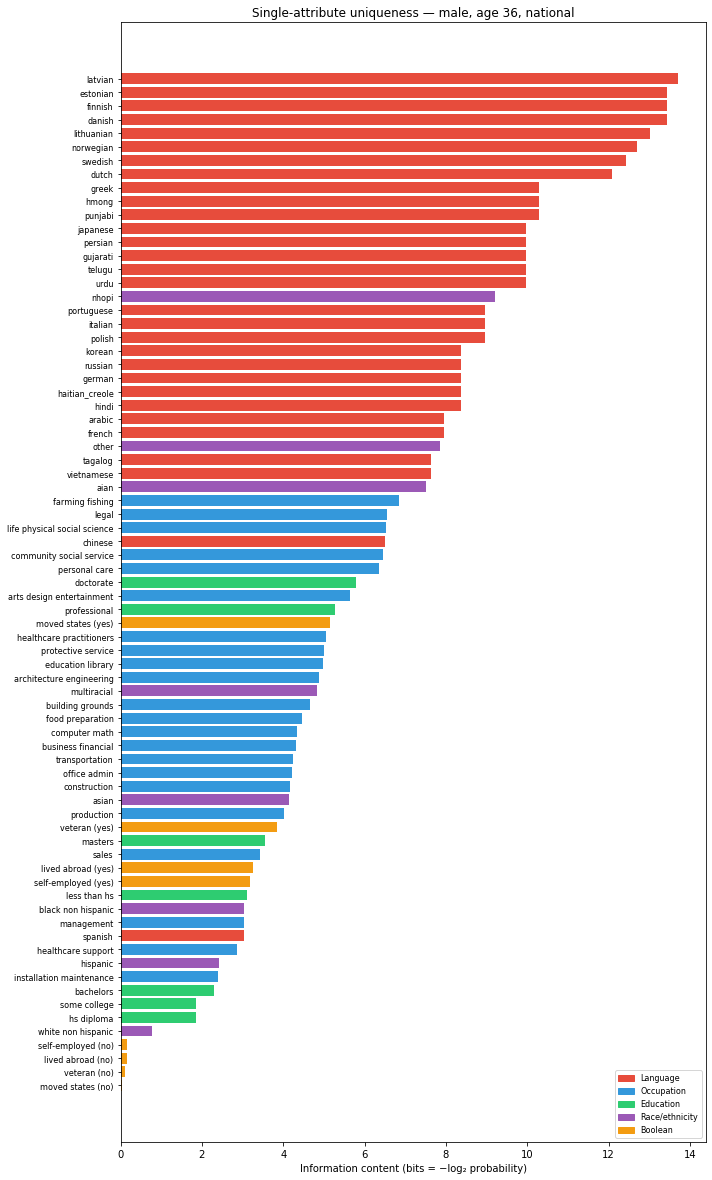


Top 10 most uniquefying attribute values:
  Language        latvian                             13.7 bits  (1 in 13,333)
  Language        estonian                            13.4 bits  (1 in 11,111)
  Language        finnish                             13.4 bits  (1 in 11,111)
  Language        danish                              13.4 bits  (1 in 11,111)
  Language        lithuanian                          13.0 bits  (1 in 8,333)
  Language        norwegian                           12.7 bits  (1 in 6,667)
  Language        swedish                             12.4 bits  (1 in 5,556)
  Language        dutch                               12.1 bits  (1 in 4,348)
  Language        greek                               10.3 bits  (1 in 1,250)
  Language        hmong                               10.3 bits  (1 in 1,250)


In [2]:
entries = []  # (label, bits, category)

# ── Race/ethnicity ────────────────────────────────────────────────────────────
for race in ['white_non_hispanic','hispanic','black_non_hispanic','asian',
             'aian','nhopi','multiracial','other']:
    p = census.get_race_rate(race)
    if p > 0:
        entries.append((race.replace('_',' '), -math.log2(p), 'Race/ethnicity'))

# ── Education ─────────────────────────────────────────────────────────────────
for edu in ['less_than_hs','hs_diploma','some_college','bachelors','masters','professional','doctorate']:
    p = census.get_education_rate(edu, REF_SEX)
    if p > 0:
        entries.append((edu.replace('_',' '), -math.log2(p), 'Education'))

# ── Occupation ────────────────────────────────────────────────────────────────
for occ in ['management','business_financial','computer_math','architecture_engineering',
            'life_physical_social_science','community_social_service','legal',
            'education_library','arts_design_entertainment','healthcare_practitioners',
            'healthcare_support','protective_service','food_preparation','building_grounds',
            'personal_care','sales','office_admin','farming_fishing','construction',
            'installation_maintenance','production','transportation']:
    p = census.get_occupation_rate(occ, REF_SEX)
    if p > 0:
        entries.append((occ.replace('_',' '), -math.log2(p), 'Occupation'))

# ── Languages ─────────────────────────────────────────────────────────────────
lang_path = Path('../data/reference/language_rates.csv')
with open(lang_path) as f:
    langs = [r for r in csv.DictReader(row for row in f if not row.startswith('#'))]
for row in langs:
    if row['language'] == 'any_non_english':
        continue
    p = float(row['rate'])
    if p > 0:
        entries.append((row['language'], -math.log2(p), 'Language'))

# ── Boolean attrs ─────────────────────────────────────────────────────────────
bool_fns = [
    ('veteran (yes)',        bls.get_veteran_rate(REF_AGE, REF_SEX)),
    ('veteran (no)',         1 - bls.get_veteran_rate(REF_AGE, REF_SEX)),
    ('self-employed (yes)',  bls.get_selfemployment_rate(REF_AGE, REF_SEX)),
    ('self-employed (no)',   1 - bls.get_selfemployment_rate(REF_AGE, REF_SEX)),
    ('moved states (yes)',   bls.get_moved_states_rate(REF_AGE)),
    ('moved states (no)',    1 - bls.get_moved_states_rate(REF_AGE)),
    ('lived abroad (yes)',   bls.get_lived_abroad_rate(REF_AGE)),
    ('lived abroad (no)',    1 - bls.get_lived_abroad_rate(REF_AGE)),
]
for label, p in bool_fns:
    if 0 < p < 1:
        entries.append((label, -math.log2(p), 'Boolean'))

# ── Plot ──────────────────────────────────────────────────────────────────────
entries.sort(key=lambda x: x[1], reverse=True)

cat_colors = {
    'Language':      '#e74c3c',
    'Occupation':    '#3498db',
    'Education':     '#2ecc71',
    'Race/ethnicity':'#9b59b6',
    'Boolean':       '#f39c12',
}

labels = [e[0] for e in entries]
bits   = [e[1] for e in entries]
colors = [cat_colors[e[2]] for e in entries]

fig, ax = plt.subplots(figsize=(10, max(6, len(labels)*0.22)))
ax.barh(range(len(labels)), bits, color=colors)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Information content (bits = −log₂ probability)')
ax.set_title(f'Single-attribute uniqueness — {REF_SEX}, age {REF_AGE}, national')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k,v in cat_colors.items()], fontsize=8)
plt.tight_layout()
plt.show()

print('\nTop 10 most uniquefying attribute values:')
for label, bits_, cat in entries[:10]:
    print(f'  {cat:15s} {label:35s} {bits_:.1f} bits  (1 in {2**bits_:,.0f})')

## 2. Language Deep Dive

How much does each language multiply your uniqueness? And what happens when you stack them?

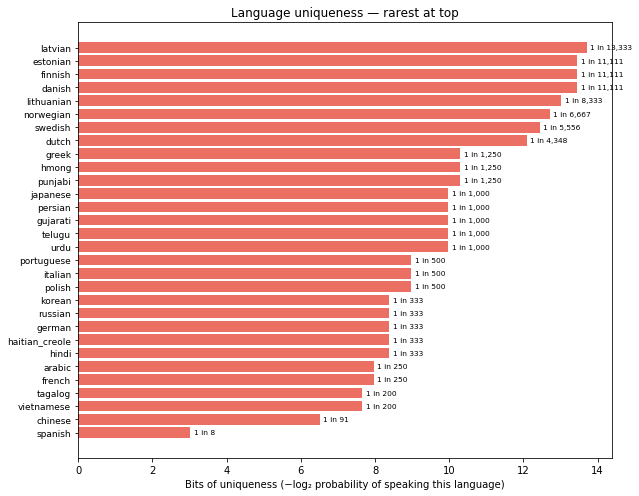


Cumulative 1-in-N for ref profile + top-5 rarest languages (stacked):
  baseline:  1 in 288,772,817  (0.039 expected matches)
  + ['latvian']:  1 in 3,850,304,231,430
  + ['latvian', 'estonian']:  1 in 42,781,158,127,001,664
  + ['latvian', 'estonian', 'finnish']:  1 in 475,346,201,411,132,784,640
  + ['latvian', 'estonian', 'finnish', 'danish']:  1 in 5,281,624,460,123,694,604,222,464
  + ['latvian', 'estonian', 'finnish', 'danish', 'lithuanian']:  1 in 44,013,537,167,697,479,825,738,432,512


In [3]:
# All languages sorted by rarity
lang_entries = sorted(
    [(r['language'], float(r['rate'])) for r in langs if r['language'] != 'any_non_english'],
    key=lambda x: x[1]
)

lang_names = [l[0] for l in lang_entries]
lang_probs = [l[1] for l in lang_entries]
lang_bits  = [-math.log2(p) for p in lang_probs]

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(range(len(lang_names)), lang_bits, color='#e74c3c', alpha=0.8)
ax.set_yticks(range(len(lang_names)))
ax.set_yticklabels(lang_names, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Bits of uniqueness (−log₂ probability of speaking this language)')
ax.set_title('Language uniqueness — rarest at top')

for i, b in enumerate(lang_bits):
    ax.text(b + 0.1, i, f'1 in {2**b:,.0f}', va='center', fontsize=7.5)

plt.tight_layout()
plt.show()

# Impact of stacking languages on the reference profile
print('\nCumulative 1-in-N for ref profile + top-5 rarest languages (stacked):')
base = score(REF_PROFILE)
print(f'  baseline:  1 in {1/base["joint_prob"]:,.0f}  ({base["expected_matches"]:.3f} expected matches)')
top5_langs = [l[0] for l in lang_entries[:5]]
for i in range(1, 6):
    profile = dict(REF_PROFILE)
    profile['demographics'] = dict(REF_PROFILE['demographics'])
    profile['demographics']['languages'] = list(top5_langs[:i])
    j = score(profile)
    print(f'  + {top5_langs[:i]}:  1 in {1/j["joint_prob"]:,.0f}')

## 3. State Sweep — Same Profile Across All 52 States

*First run takes ~1–2 min (Census API). Subsequent runs are instant (cached).*

Running state sweep (first run hits Census API per state)...
  WY done (0.000 expected)
Done. 52 states.


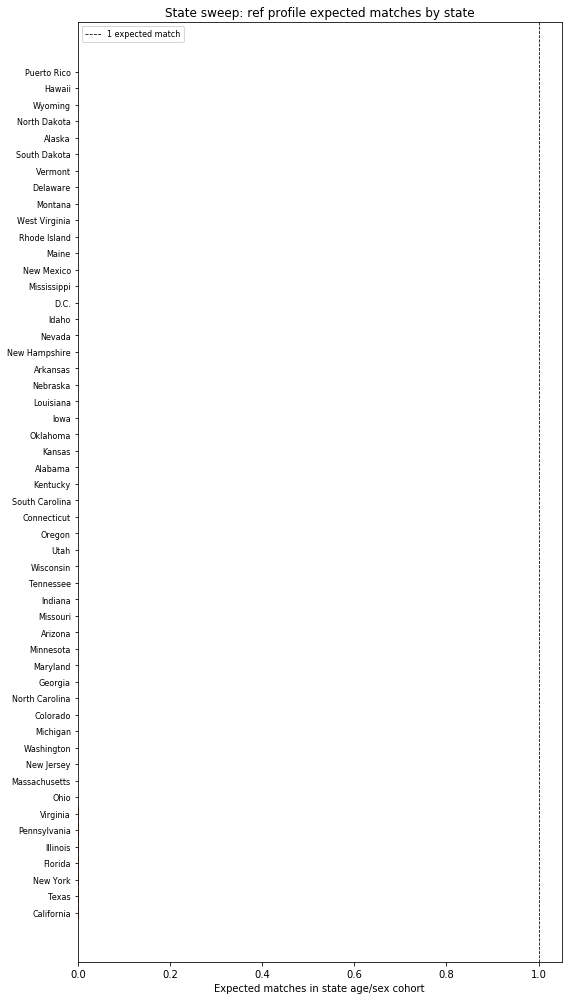


5 most unique states for this profile:
  Puerto Rico           0.0000 expected  (cohort 87,905)
  Hawaii                0.0001 expected  (cohort 51,478)
  Wyoming               0.0001 expected  (cohort 20,555)
  North Dakota          0.0001 expected  (cohort 27,857)
  Alaska                0.0001 expected  (cohort 28,047)

5 least unique states:
  Illinois              0.0017 expected  (cohort 433,926)
  Florida               0.0020 expected  (cohort 686,334)
  New York              0.0026 expected  (cohort 660,272)
  Texas                 0.0027 expected  (cohort 1,047,707)
  California            0.0036 expected  (cohort 1,431,803)


In [4]:
print('Running state sweep (first run hits Census API per state)...')
state_results = {}
for abbr in STATE_FIPS:
    j = score(REF_PROFILE, state=abbr)
    state_results[abbr] = {
        'expected':    j['expected_matches'],
        'joint_prob':  j['joint_prob'],
        'cohort_size': j['cohort_size'],
    }
    print(f'  {abbr.upper()} done ({j["expected_matches"]:.3f} expected)', end='\r')

print(f'\nDone. {len(state_results)} states.')

# Sort by expected_matches ascending (rarest first)
sorted_states = sorted(state_results.items(), key=lambda x: x[1]['expected'])
abbrs  = [s[0] for s in sorted_states]
names  = [STATE_NAMES[a] for a in abbrs]
exp    = [s[1]['expected'] for s in sorted_states]

fig, ax = plt.subplots(figsize=(8, 14))
colors = ['#e74c3c' if e < 1 else '#3498db' for e in exp]
ax.barh(range(len(names)), exp, color=colors)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=8)
ax.invert_yaxis()
ax.axvline(1.0, color='black', linestyle='--', linewidth=0.8, label='1 expected match')
ax.set_xlabel('Expected matches in state age/sex cohort')
ax.set_title('State sweep: ref profile expected matches by state')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('\n5 most unique states for this profile:')
for abbr, r in sorted_states[:5]:
    print(f'  {STATE_NAMES[abbr]:20s}  {r["expected"]:.4f} expected  (cohort {r["cohort_size"]:,})')
print('\n5 least unique states:')
for abbr, r in sorted_states[-5:]:
    print(f'  {STATE_NAMES[abbr]:20s}  {r["expected"]:.4f} expected  (cohort {r["cohort_size"]:,})')

## 4. State Sensitivity Heatmap

Which attribute drives the uniqueness difference between states?

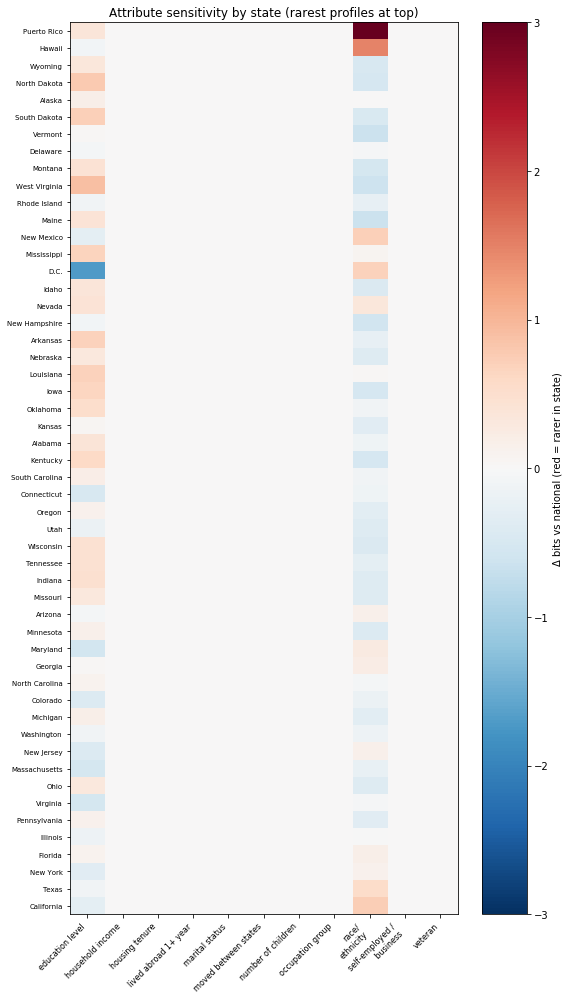

In [5]:
national_attrs = {r.name: r.prob for r in compute_attribute_probs(REF_PROFILE, state=None)}
attr_names = sorted(national_attrs.keys())

# delta_bits[state][attr] = log2(state_prob) - log2(national_prob)
# positive = rarer in this state, negative = more common
delta_matrix = []
state_labels = []
for abbr, _ in sorted_states:   # already sorted rarest-first
    state_attrs = {r.name: r.prob for r in compute_attribute_probs(REF_PROFILE, state=abbr)}
    row = []
    for name in attr_names:
        nat = national_attrs.get(name, 0)
        sta = state_attrs.get(name, 0)
        if nat > 0 and sta > 0:
            row.append(math.log2(nat) - math.log2(sta))  # positive = rarer in state
        else:
            row.append(0.0)
    delta_matrix.append(row)
    state_labels.append(STATE_NAMES[abbr])

Z = np.array(delta_matrix)
fig, ax = plt.subplots(figsize=(max(8, len(attr_names)*0.7), 14))
im = ax.imshow(Z, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3)
ax.set_xticks(range(len(attr_names)))
ax.set_xticklabels([n.replace('/','/\n') for n in attr_names], rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(state_labels)))
ax.set_yticklabels(state_labels, fontsize=7)
plt.colorbar(im, ax=ax, label='Δ bits vs national (red = rarer in state)')
ax.set_title('Attribute sensitivity by state (rarest profiles at top)')
plt.tight_layout()
plt.show()

## 5. The Most Average American

What profile minimizes uniqueness — and how does it compare to the reference?

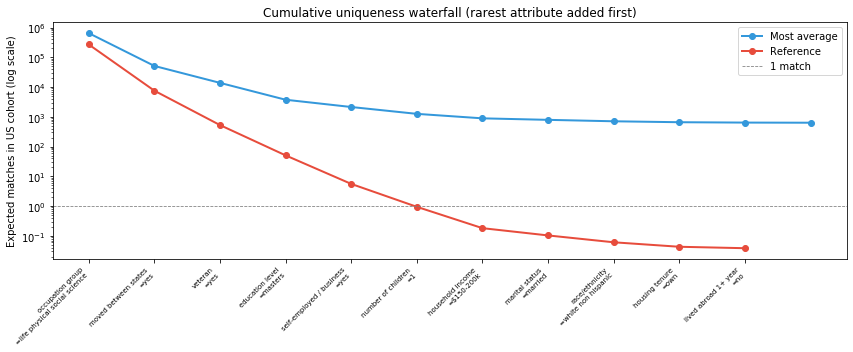

Most average American:  633.80 expected matches
Reference profile:      0.0386 expected matches
Reference is 16431x more unique than average


In [6]:
AVERAGE_PROFILE = {
    'meta': {'name': 'Average', 'age': REF_AGE, 'sex': REF_SEX},
    'demographics': {
        'race_ethnicity':   'white_non_hispanic',   # 58.9%
        'education_level':  'hs_diploma',            # ~26% male
        'occupation_group': 'office_admin',          # ~14% male
        'household_income': 50000,                   # modal bracket
        'languages': [],
    },
    'family': {
        'marital_status': 'married',   # ~50% at 35-39
        'num_children':   2,
        'housing_tenure': 'own',
    },
    'life_path': {
        'veteran':            False,
        'founded_business':   False,
        'moved_states':       False,
        'lived_abroad':       False,
        'attended_grad_school': False,
    },
}

def waterfall(profile, label, ax, color):
    cohort = get_cohort_size(REF_AG, REF_SEX)
    attrs  = compute_attribute_probs(profile)
    joint  = compute_joint(attrs, cohort)
    cumul  = joint['cumulative']   # sorted rarest first
    xs     = range(len(cumul))
    ys     = [c['expected'] for c in cumul]
    xlbls  = [f"{c['name']}\n={c['value']}" for c in cumul]
    ax.plot(xs, ys, marker='o', color=color, label=label, linewidth=2)
    ax.set_xticks(xs)
    ax.set_xticklabels(xlbls, rotation=45, ha='right', fontsize=7)
    return joint['expected_matches']

fig, ax = plt.subplots(figsize=(12, 5))
avg_exp = waterfall(AVERAGE_PROFILE, 'Most average', ax, '#3498db')
ref_exp = waterfall(REF_PROFILE,     'Reference',    ax, '#e74c3c')
ax.set_yscale('log')
ax.set_ylabel('Expected matches in US cohort (log scale)')
ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8, label='1 match')
ax.set_title('Cumulative uniqueness waterfall (rarest attribute added first)')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Most average American:  {avg_exp:.2f} expected matches')
print(f'Reference profile:      {ref_exp:.4f} expected matches')
print(f'Reference is {avg_exp/max(ref_exp,1e-10):.0f}x more unique than average')

## 6. Rarest Combination Hunt

Grid search over education × language × state. How many people have a doctorate AND speak Latvian AND live in Mississippi?

In [7]:
top_rare_langs = [l[0] for l in lang_entries[:6]]   # 6 rarest languages
edu_levels = ['bachelors', 'masters', 'professional', 'doctorate']
focus_states = ['ms', 'wv', 'ar', 'ca', 'ma', 'wa', None]   # None = national

combos = []
for edu in edu_levels:
    for lang in top_rare_langs:
        for state in focus_states:
            p = dict(REF_PROFILE)
            p['demographics'] = dict(REF_PROFILE['demographics'])
            p['demographics']['education_level'] = edu
            p['demographics']['languages'] = [lang]
            j = score(p, state=state)
            combos.append({
                'edu': edu, 'lang': lang,
                'state': STATE_NAMES[state] if state else 'US',
                'expected': j['expected_matches'],
                'one_in_n': int(1/j['joint_prob']) if j['joint_prob'] > 0 else 0,
            })

combos.sort(key=lambda x: x['expected'])

print(f'Top 20 rarest combinations (edu × language × state):')
print(f'{"Education":15s}  {"Language":12s}  {"State":15s}  {"Expected":>10s}  {"1 in N":>15s}')
print('-' * 72)
for c in combos[:20]:
    exp_str = f"{c['expected']:.4f}" if c['expected'] >= 0.0001 else '<0.0001'
    print(f"{c['edu']:15s}  {c['lang']:12s}  {c['state']:15s}  {exp_str:>10s}  1 in {c['one_in_n']:>12,}")

Top 20 rarest combinations (edu × language × state):
Education        Language      State              Expected           1 in N
------------------------------------------------------------------------
professional     latvian       West Virginia       <0.0001  1 in 25,527,434,570,196
professional     estonian      West Virginia       <0.0001  1 in 21,272,862,141,830
professional     finnish       West Virginia       <0.0001  1 in 21,272,862,141,830
professional     danish        West Virginia       <0.0001  1 in 21,272,862,141,830
professional     latvian       Mississippi         <0.0001  1 in 33,510,847,499,516
professional     estonian      Mississippi         <0.0001  1 in 27,925,706,249,596
professional     finnish       Mississippi         <0.0001  1 in 27,925,706,249,596
professional     danish        Mississippi         <0.0001  1 in 27,925,706,249,596
professional     latvian       Arkansas            <0.0001  1 in 28,979,050,563,481
professional     lithuanian    West Virgin

## 7. Race × Education Matrix

The state sensitivity heatmap lights up on exactly two axes: **race/ethnicity** and **education level**. Every other attribute — occupation, income, tenure, marital status, booleans — is either flat across states or contributes so little that it disappears in the noise.

This isn't a coincidence. Race and education are the two attributes where both:
1. Base rates vary enormously across their possible values (doctorate: ~2%, some college: ~28%)
2. Rates differ substantially by state (master's: ~7% in Mississippi vs ~17% in Massachusetts)

And they're not independent — P(education | race) diverges meaningfully from P(education) alone.

The matrix below shows **P(education | race, sex)** — the conditional rate *within* each race group, normalized so population size doesn't inflate white cells. Each cell answers: *among men 35–39 of this race, what fraction holds this degree?*

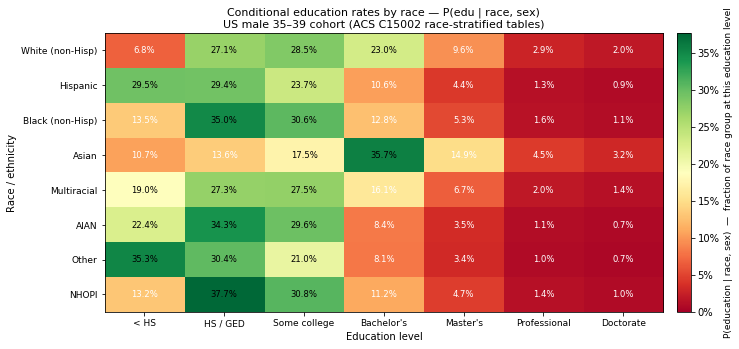

5 rarest race x education combinations (by conditional rate):
  other                   x  doctorate       0.72%
  aian                    x  doctorate       0.74%
  hispanic                x  doctorate       0.94%
  nhopi                   x  doctorate       0.99%
  other                   x  professional    1.02%

5 most common:
  nhopi                   x  hs_diploma      37.7%
  asian                   x  bachelors       35.7%
  other                   x  less_than_hs    35.3%
  black_non_hispanic      x  hs_diploma      35.0%
  aian                    x  hs_diploma      34.3%


In [8]:
from data.census import get_education_rate_by_race, get_education_rate

RACES = [
    ('white_non_hispanic', 'White (non-Hisp)'),
    ('hispanic',           'Hispanic'),
    ('black_non_hispanic', 'Black (non-Hisp)'),
    ('asian',              'Asian'),
    ('multiracial',        'Multiracial'),
    ('aian',               'AIAN'),
    ('other',              'Other'),
    ('nhopi',              'NHOPI'),
]

EDUS = [
    ('less_than_hs',  '< HS'),
    ('hs_diploma',    'HS / GED'),
    ('some_college',  'Some college'),
    ('bachelors',     "Bachelor's"),
    ('masters',       "Master's"),
    ('professional',  'Professional'),
    ('doctorate',     'Doctorate'),
]

# P(education | race, sex) — normalized within each race group
grid = np.zeros((len(RACES), len(EDUS)))
for i, (race, _) in enumerate(RACES):
    for j, (edu, _) in enumerate(EDUS):
        p = get_education_rate_by_race(edu, race, REF_SEX, state=None)
        if p is None:
            p = get_education_rate(edu, REF_SEX, state=None)
        grid[i, j] = p

race_labels = [r[1] for r in RACES]
edu_labels  = [e[1] for e in EDUS]

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(grid, aspect='auto', cmap='RdYlGn', vmin=0)

ax.set_xticks(range(len(EDUS)))
ax.set_xticklabels(edu_labels, fontsize=9)
ax.set_yticks(range(len(RACES)))
ax.set_yticklabels(race_labels, fontsize=9)

# Annotate each cell with the percentage
for i in range(len(RACES)):
    for j in range(len(EDUS)):
        v = grid[i, j]
        brightness = v / grid.max()
        fc = 'black' if brightness > 0.45 else 'white'
        ax.text(j, i, f'{v*100:.1f}%', ha='center', va='center', fontsize=8.5, color=fc)

cbar = plt.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('P(education | race, sex)  —  fraction of race group at this education level', fontsize=9)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))

ax.set_xlabel('Education level', fontsize=10)
ax.set_ylabel('Race / ethnicity', fontsize=10)
ax.set_title(
    'Conditional education rates by race — P(edu | race, sex)\n'
    'US male 35–39 cohort (ACS C15002 race-stratified tables)',
    fontsize=11
)
plt.tight_layout()
plt.show()

# Print extremes
flat_idx = np.argsort(grid.ravel())
print('5 rarest race x education combinations (by conditional rate):')
for k in flat_idx[:5]:
    i, j = divmod(k, len(EDUS))
    print(f'  {RACES[i][0]:22s}  x  {EDUS[j][0]:14s}  {grid[i,j]*100:.2f}%')
print('\n5 most common:')
for k in flat_idx[-5:][::-1]:
    i, j = divmod(k, len(EDUS))
    print(f'  {RACES[i][0]:22s}  x  {EDUS[j][0]:14s}  {grid[i,j]*100:.1f}%')


## 8. Language × Education Correlation

Does speaking a second language predict higher educational attainment?

The confound: the US non-English-speaking population skews heavily foreign-born. Recent immigrants are often underrepresented in domestic degree counts even when highly educated — so a raw English vs. non-English comparison would conflate "learned a language" with "immigrated."

The fix: ACS PUMS microdata (California, individual-level records) lets us split by **nativity**. The group that tests Simon's hypothesis is **native-born non-English speakers** — people who acquired a second language through upbringing or schooling, not immigration. If *that* group shows higher BA+ rates than native-born English-only speakers, the correlation is real and the immigration confound is not the explanation.

In [9]:
import zipfile, io, pickle, pandas as pd, sys, requests as _req
from pathlib import Path

sys.path.insert(0, '..')

PUMS_CACHE = Path('../data/cache/pums_lang_edu_ca.pkl')
PUMS_URL   = 'https://www2.census.gov/programs-surveys/acs/data/pums/2022/5-Year/csv_pca.zip'
NEEDED     = {'AGEP', 'LANX', 'NATIVITY', 'SCHL', 'PWGTP'}

if PUMS_CACHE.exists():
    df = pickle.loads(PUMS_CACHE.read_bytes())
    print(f'Loaded from cache: {len(df):,} adult records (CA PUMS 2022)')
else:
    print('Downloading CA PUMS person file (~150MB, one-time)...')
    with _req.get(PUMS_URL, stream=True, timeout=(60, None)) as r:
        r.raise_for_status()
        total_mb = int(r.headers.get('content-length', 0)) // 1_000_000
        buf, done = io.BytesIO(), 0
        for chunk in r.iter_content(chunk_size=2_000_000):
            buf.write(chunk); done += len(chunk)
            print(f'  {done//1_000_000}MB / {total_mb}MB', end='\r')
    print('\nExtracting...')
    buf.seek(0)
    with zipfile.ZipFile(buf) as z:
        csv_name = next(n for n in z.namelist() if n.lower().endswith('.csv'))
        with z.open(csv_name) as f:
            df = pd.read_csv(f, usecols=lambda c: c in NEEDED, dtype=str, low_memory=False)
    df = df.dropna(subset=list(NEEDED))
    df['AGEP']  = df['AGEP'].astype(int)
    df['PWGTP'] = df['PWGTP'].astype(float)
    df['SCHL']  = df['SCHL'].astype(int)
    df = df[df['AGEP'] >= 25].copy()
    PUMS_CACHE.write_bytes(pickle.dumps(df))
    print(f'Cached. {len(df):,} adult records.')

# LANX 1 = speaks non-English at home; 2 = English only
# NATIVITY 1 = native-born; 2 = foreign-born
# SCHL >= 21 = bachelor's or higher (21=BA, 22=MA, 23=prof, 24=PhD)
df['speaks_other'] = df['LANX'] == '1'
df['native']       = df['NATIVITY'] == '1'
df['ba_plus']      = df['SCHL'] >= 21

def ba_rate(mask):
    g = df[mask]
    w = g['PWGTP']
    return (g['ba_plus'] * w).sum() / w.sum(), w.sum()

GROUPS = [
    ('Native / English-only',       df['native'] & ~df['speaks_other']),
    ('Native / non-English speaker',df['native'] &  df['speaks_other']),
    ('Foreign-born / non-English',  ~df['native'] &  df['speaks_other']),
    ('Foreign-born / English-only', ~df['native'] & ~df['speaks_other']),
]

labels_g, rates, ns = [], [], []
for label, mask in GROUPS:
    r, n = ba_rate(mask)
    labels_g.append(label)
    rates.append(r * 100)
    ns.append(n)

# ── Chart ──────────────────────────────────────────────────────────────────
colors_g = ['#3498db', '#2ecc71', '#e74c3c', '#95a5a6']
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(range(len(labels_g)), rates, color=colors_g, alpha=0.88)
ax.set_yticks(range(len(labels_g)))
ax.set_yticklabels(labels_g, fontsize=10)
ax.set_xlabel('BA+ attainment rate (%)', fontsize=10)
ax.set_title('Does native bilingualism predict higher education?\n'
             'CA adults 25+ — ACS PUMS 2022 (weighted)', fontsize=11)
for i, (rate, n) in enumerate(zip(rates, ns)):
    ax.text(rate + 0.3, i, f'{rate:.1f}%  (wtd n={n/1e6:.2f}M)', va='center', fontsize=9)
ax.set_xlim(0, max(rates) * 1.4)
# Highlight the hypothesis-testing group
ax.get_yticklabels()[1].set_fontweight('bold')
ax.get_yticklabels()[1].set_color('#27ae60')
plt.tight_layout()
plt.show()

# ── Verdict ────────────────────────────────────────────────────────────────
native_eng = rates[0]
native_bi  = rates[1]
diff = native_bi - native_eng
print(f'\nNative-born English-only:     {native_eng:.1f}% BA+')
print(f'Native-born non-English spkr: {native_bi:.1f}% BA+  <-- hypothesis test')
print(f'Difference: {abs(diff):.1f} pp {"higher" if diff > 0 else "lower"} for native bilinguals')
print()
if diff > 3:
    print('RESULT: Native bilingualism correlates with substantially higher BA+ attainment.')
    print('The correlation persists after controlling for immigration status.')
elif diff > 0:
    print('RESULT: Weak positive correlation — direction supports hypothesis but effect is small.')
else:
    print('RESULT: Negative or null correlation in this state sample.')


KeyboardInterrupt: 